In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

dataset = pd.read_csv('/content/Churn_Modelling.csv')

print("First five rows:")
display(dataset.head())

print("Dataset size:", dataset.shape)

print("Column names:")
print(dataset.columns.tolist())

print("Missing values:")
print(dataset.isnull().sum())

First five rows:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Dataset size: (10000, 14)
Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Missing values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [ ]:

# Remove columns that do not help predict churn
data = dataset.drop(
    columns=['RowNumber', 'CustomerId', 'Surname']
)

# Separate inputs and target
X = data.drop(columns=['Exited'])
y = data['Exited']

# Convert categorical columns into numeric columns
X = pd.get_dummies(
    X,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

print("Prepared feature data:")
display(X.head())

print("Target values:")
print(y.value_counts())

Prepared feature data:


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


Target values:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [ ]:

# Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [ ]:

models = {
    "Logistic Regression": (
        lr_model, X_test_scaled
    ),
    "Random Forest": (
        rf_model, X_test
    )
}

for name, (model, test_data) in models.items():
    predictions = model.predict(test_data)

    print("\n", name)
    print("Accuracy:", round(
        accuracy_score(y_test, predictions), 4
    ))
    print(classification_report(
        y_test, predictions, zero_division=0
    ))


 Logistic Regression
Accuracy: 0.808
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000


 Random Forest
Accuracy: 0.8615
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.79      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000



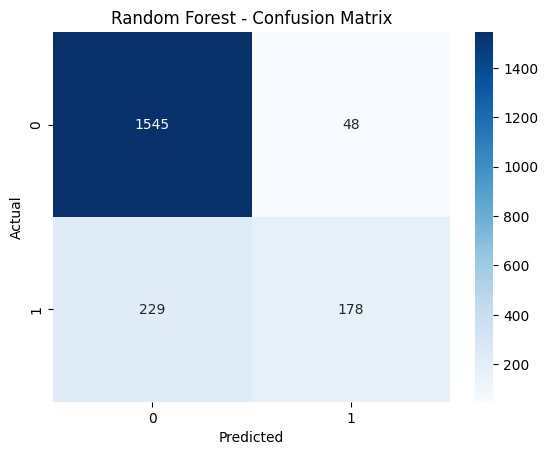

In [ ]:

predictions = rf_model.predict(X_test)

cm = confusion_matrix(y_test, predictions)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Overall customer churn rate: 20.37%

Customer status counts:
Exited
0    7963
1    2037
Name: count, dtype: int64

Churn rate by geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64

Churn rate by gender:
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


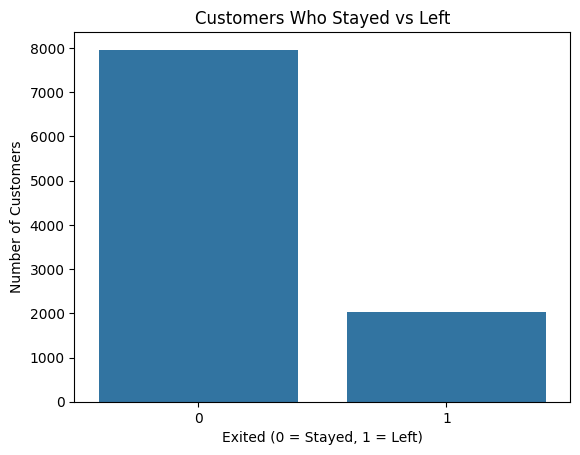

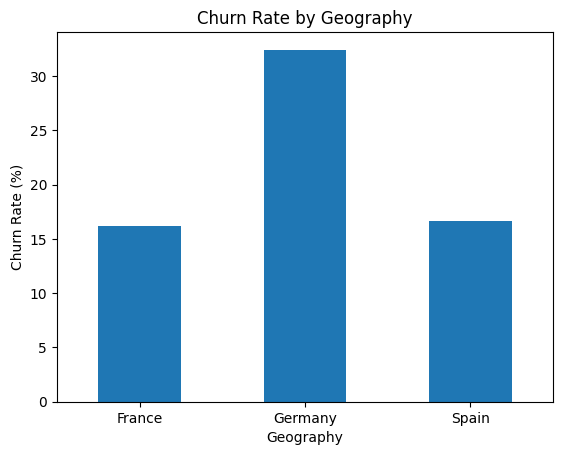

In [ ]:

# RETENTION ANALYTICS

# 1. Calculate overall churn rate
churn_rate = dataset['Exited'].mean() * 100

print(f"Overall customer churn rate: {churn_rate:.2f}%")

# 2. Compare customers who stayed and left
print("\nCustomer status counts:")
print(dataset['Exited'].value_counts())

# 3. Churn rate by geography
print("\nChurn rate by geography:")
print(
    dataset.groupby('Geography')['Exited']
    .mean().mul(100).round(2)
)

# 4. Churn rate by gender
print("\nChurn rate by gender:")
print(
    dataset.groupby('Gender')['Exited']
    .mean().mul(100).round(2)
)

# 5. Visualize customer churn
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=dataset, x='Exited')
plt.title('Customers Who Stayed vs Left')
plt.xlabel('Exited (0 = Stayed, 1 = Left)')
plt.ylabel('Number of Customers')
plt.show()

# 6. Compare churn rates across locations
geo_churn = (
    dataset.groupby('Geography')['Exited']
    .mean().mul(100)
)

geo_churn.plot(kind='bar')
plt.title('Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()